In [8]:
from pathlib import Path

for p in Path("/kaggle/input").rglob("*"):
    if p.is_dir() and p.name.lower() in ["images", "trimaps"]:
        print(p)

/kaggle/input/datasets/julinmaloof/the-oxfordiiit-pet-dataset/images
/kaggle/input/datasets/julinmaloof/the-oxfordiiit-pet-dataset/annotations/trimaps


In [9]:
from pathlib import Path
IMAGE_DIR = Path(
    "/kaggle/input/datasets/julinmaloof/the-oxfordiiit-pet-dataset/images"
)

MASK_DIR = Path(
    "/kaggle/input/datasets/julinmaloof/the-oxfordiiit-pet-dataset/annotations/trimaps"
)
MODELS_TO_RUN = ["unet", "unetpp"]
image_files = sorted(IMAGE_DIR.glob("*.jpg"))
mask_files = sorted(MASK_DIR.glob("*.png"))
print("Total Images:", len(image_files))
print("Total Masks:", len(mask_files))
print("\nSample Image:", image_files[0].name)
print("Sample Mask:", mask_files[0].name)
image_names = {p.stem for p in image_files}
mask_names = {p.stem for p in mask_files}

print("\nMatched Pairs:", len(image_names & mask_names))
print("Images Without Masks:", len(image_names - mask_names))
print("Masks Without Images:", len(mask_names - image_names))

Total Images: 7390
Total Masks: 7390

Sample Image: Abyssinian_1.jpg
Sample Mask: Abyssinian_1.png

Matched Pairs: 7390
Images Without Masks: 0
Masks Without Images: 0


Image shape: (400, 600, 3)
Mask shape: (400, 600)
Unique mask values: [1 2 3]


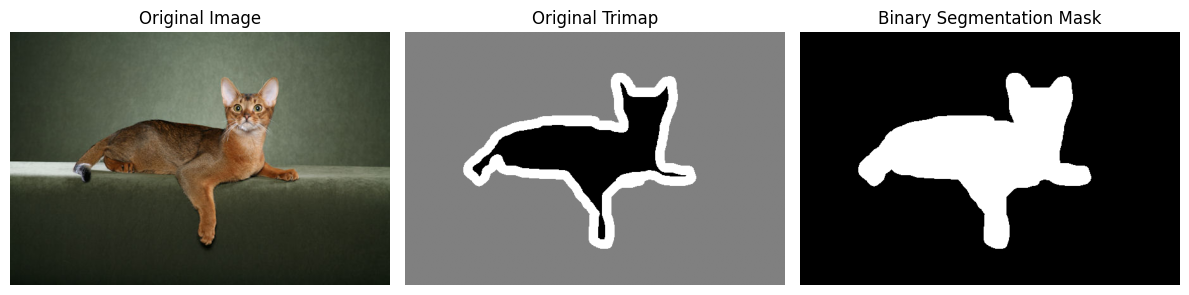

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Select a sample
image_path = image_files[0]
mask_path = MASK_DIR / (image_path.stem + ".png")

# Load image and mask
image = Image.open(image_path).convert("RGB")
mask = np.array(Image.open(mask_path))

print("Image shape:", np.array(image).shape)
print("Mask shape:", mask.shape)
print("Unique mask values:", np.unique(mask))

# Convert trimap to binary mask
binary_mask = np.where(mask == 2, 0, 1).astype(np.uint8)

# Display
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Original Trimap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(binary_mask, cmap="gray")
plt.title("Binary Segmentation Mask")
plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from PIL import Image

# Configuration
IMAGE_SIZE = 256
BATCH_SIZE = 16
NUM_WORKERS = 2

# Image transformation
image_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class OxfordPetDataset(Dataset):

    def __init__(self, image_paths, mask_dir):
        self.image_paths = image_paths
        self.mask_dir = mask_dir

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):

        image_path = self.image_paths[idx]
        mask_path = self.mask_dir / (image_path.stem + ".png")

        # Load image
        image = Image.open(image_path).convert("RGB")

        # Load mask
        mask = Image.open(mask_path)

        # Resize image
        image = image_transform(image)

        # Resize mask using nearest-neighbor interpolation
        mask = mask.resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.NEAREST
        )

        mask = np.array(mask)

        # Binary segmentation: pet + boundary = 1, background = 0
        mask = np.where(mask == 2, 0, 1).astype(np.float32)

        mask = torch.from_numpy(mask).unsqueeze(0)

        return image, mask


# Create complete dataset
dataset = OxfordPetDataset(image_files, MASK_DIR)

# Split: 70% training, 15% validation, 15% testing
total_size = len(dataset)

train_size = int(0.70 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

# Verify one batch
images, masks = next(iter(train_loader))

print("\nImage batch shape:", images.shape)
print("Mask batch shape:", masks.shape)
print("Mask unique values:", torch.unique(masks))

Training samples: 5173
Validation samples: 1108
Testing samples: 1109

Image batch shape: torch.Size([16, 3, 256, 256])
Mask batch shape: torch.Size([16, 1, 256, 256])
Mask unique values: tensor([0., 1.])


In [14]:
import torch
import torch.nn as nn


# Double Convolution Block
class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):

        super().__init__()

        self.conv = nn.Sequential(

            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


# U-Net Model
class UNet(nn.Module):

    def __init__(self, in_channels=3, out_channels=1):

        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(in_channels, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)

        # Bottleneck
        self.bottleneck = DoubleConv(512, 1024)

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Decoder
        self.up4 = nn.ConvTranspose2d(
            1024, 512, kernel_size=2, stride=2
        )
        self.dec4 = DoubleConv(1024, 512)

        self.up3 = nn.ConvTranspose2d(
            512, 256, kernel_size=2, stride=2
        )
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(
            256, 128, kernel_size=2, stride=2
        )
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(
            128, 64, kernel_size=2, stride=2
        )
        self.dec1 = DoubleConv(128, 64)

        # Final segmentation layer
        self.final = nn.Conv2d(
            64, out_channels, kernel_size=1
        )

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(self.pool(e4))

        # Decoder + Skip Connections
        d4 = self.up4(b)
        d4 = torch.cat([d4, e4], dim=1)
        d4 = self.dec4(d4)

        d3 = self.up3(d4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        # Raw logits (no sigmoid here)
        output = self.final(d1)

        return output

In [15]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

unet = UNet(
    in_channels=3,
    out_channels=1
).to(device)

# Test with one batch
images, masks = next(iter(train_loader))

images = images.to(device)

with torch.no_grad():
    output = unet(images)

print("Device:", device)
print("Input shape:", images.shape)
print("Output shape:", output.shape)
print("Total parameters:", sum(
    p.numel() for p in unet.parameters()
))

Device: cuda
Input shape: torch.Size([16, 3, 256, 256])
Output shape: torch.Size([16, 1, 256, 256])
Total parameters: 31043521


In [16]:
import torch
import torch.nn as nn


class UNetPlusPlus(nn.Module):

    def __init__(self, in_channels=3, out_channels=1):

        super().__init__()

        # Feature channels
        filters = [32, 64, 128, 256, 512]

        # Encoder
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.conv0_0 = DoubleConv(in_channels, filters[0])
        self.conv1_0 = DoubleConv(filters[0], filters[1])
        self.conv2_0 = DoubleConv(filters[1], filters[2])
        self.conv3_0 = DoubleConv(filters[2], filters[3])
        self.conv4_0 = DoubleConv(filters[3], filters[4])

        # Nested skip pathways
        self.conv0_1 = DoubleConv(filters[0] + filters[1], filters[0])
        self.conv1_1 = DoubleConv(filters[1] + filters[2], filters[1])
        self.conv2_1 = DoubleConv(filters[2] + filters[3], filters[2])
        self.conv3_1 = DoubleConv(filters[3] + filters[4], filters[3])

        self.conv0_2 = DoubleConv(filters[0] * 2 + filters[1], filters[0])
        self.conv1_2 = DoubleConv(filters[1] * 2 + filters[2], filters[1])
        self.conv2_2 = DoubleConv(filters[2] * 2 + filters[3], filters[2])

        self.conv0_3 = DoubleConv(filters[0] * 3 + filters[1], filters[0])
        self.conv1_3 = DoubleConv(filters[1] * 3 + filters[2], filters[1])

        self.conv0_4 = DoubleConv(filters[0] * 4 + filters[1], filters[0])

        # Upsampling
        self.up = nn.Upsample(
            scale_factor=2,
            mode="bilinear",
            align_corners=True
        )

        # Final segmentation layer
        self.final = nn.Conv2d(
            filters[0], out_channels, kernel_size=1
        )

    def forward(self, x):

        # Encoder
        x0_0 = self.conv0_0(x)
        x1_0 = self.conv1_0(self.pool(x0_0))
        x2_0 = self.conv2_0(self.pool(x1_0))
        x3_0 = self.conv3_0(self.pool(x2_0))
        x4_0 = self.conv4_0(self.pool(x3_0))

        # First nested level
        x0_1 = self.conv0_1(torch.cat([
            x0_0, self.up(x1_0)
        ], dim=1))

        x1_1 = self.conv1_1(torch.cat([
            x1_0, self.up(x2_0)
        ], dim=1))

        x2_1 = self.conv2_1(torch.cat([
            x2_0, self.up(x3_0)
        ], dim=1))

        x3_1 = self.conv3_1(torch.cat([
            x3_0, self.up(x4_0)
        ], dim=1))

        # Second nested level
        x0_2 = self.conv0_2(torch.cat([
            x0_0, x0_1, self.up(x1_1)
        ], dim=1))

        x1_2 = self.conv1_2(torch.cat([
            x1_0, x1_1, self.up(x2_1)
        ], dim=1))

        x2_2 = self.conv2_2(torch.cat([
            x2_0, x2_1, self.up(x3_1)
        ], dim=1))

        # Third nested level
        x0_3 = self.conv0_3(torch.cat([
            x0_0, x0_1, x0_2, self.up(x1_2)
        ], dim=1))

        x1_3 = self.conv1_3(torch.cat([
            x1_0, x1_1, x1_2, self.up(x2_2)
        ], dim=1))

        # Fourth nested level
        x0_4 = self.conv0_4(torch.cat([
            x0_0, x0_1, x0_2, x0_3, self.up(x1_3)
        ], dim=1))

        # Final output
        output = self.final(x0_4)

        return output

In [17]:
unetpp = UNetPlusPlus(
    in_channels=3,
    out_channels=1
).to(device)

images, masks = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    output = unetpp(images)

print("Device:", device)
print("Input shape:", images.shape)
print("Output shape:", output.shape)

print("Total parameters:", sum(
    p.numel() for p in unetpp.parameters()
))

Device: cuda
Input shape: torch.Size([16, 3, 256, 256])
Output shape: torch.Size([16, 1, 256, 256])
Total parameters: 9163329


In [18]:
import torch
import torch.nn as nn


# Binary Cross Entropy Loss
bce_loss = nn.BCEWithLogitsLoss()


# Dice Loss
def dice_loss(predictions, targets, smooth=1e-6):

    predictions = torch.sigmoid(predictions)

    predictions = predictions.contiguous().view(-1)
    targets = targets.contiguous().view(-1)

    intersection = (predictions * targets).sum()

    dice = (
        2.0 * intersection + smooth
    ) / (
        predictions.sum() + targets.sum() + smooth
    )

    return 1 - dice


# Combined BCE + Dice Loss
def combined_loss(predictions, targets):

    loss_bce = bce_loss(predictions, targets)
    loss_dice = dice_loss(predictions, targets)

    return loss_bce + loss_dice


# Dice Score
def dice_score(predictions, targets, threshold=0.5, smooth=1e-6):

    predictions = torch.sigmoid(predictions)
    predictions = (predictions > threshold).float()

    predictions = predictions.view(-1)
    targets = targets.view(-1)

    intersection = (predictions * targets).sum()

    dice = (
        2.0 * intersection + smooth
    ) / (
        predictions.sum() + targets.sum() + smooth
    )

    return dice.item()


# Intersection over Union (IoU)
def iou_score(predictions, targets, threshold=0.5, smooth=1e-6):

    predictions = torch.sigmoid(predictions)
    predictions = (predictions > threshold).float()

    predictions = predictions.view(-1)
    targets = targets.view(-1)

    intersection = (predictions * targets).sum()
    union = predictions.sum() + targets.sum() - intersection

    iou = (intersection + smooth) / (union + smooth)

    return iou.item()


print("Loss functions and evaluation metrics defined successfully!")

Loss functions and evaluation metrics defined successfully!


In [19]:
images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

with torch.no_grad():

    predictions = unet(images)

    loss = combined_loss(predictions, masks)

    dice = dice_score(predictions, masks)

    iou = iou_score(predictions, masks)


print("Combined Loss:", round(loss.item(), 4))
print("Dice Score:", round(dice, 4))
print("IoU Score:", round(iou, 4))

Combined Loss: 1.2772
Dice Score: 0.4365
IoU Score: 0.2792


**Due to the limited time available for completing the assignment, both models were trained for only 5 epochs instead of 20, as full training is computationally time-consuming.**

In [28]:
import torch
from torch.utils.data import DataLoader

BATCH_SIZE = 8
EPOCHS = 5
LEARNING_RATE = 1e-4
PATIENCE = 5

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

print("GPU:", torch.cuda.get_device_name(0))
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)

GPU: Tesla T4
Batch size: 8
Epochs: 5
Learning rate: 0.0001


In [23]:
import os
import time
import gc
import torch
from tqdm.auto import tqdm


def train_model(model, model_name):

    model = model.to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(device.type == "cuda")
    )

    best_val_loss = float("inf")
    patience_counter = 0

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_dice": [],
        "val_iou": []
    }

    checkpoint_path = f"/kaggle/working/best_{model_name}.pth"

    total_steps = EPOCHS * len(train_loader)
    completed_steps = 0
    overall_start = time.time()

    print(f"\nStarting {model_name.upper()} Training")

    for epoch in range(EPOCHS):

        epoch_start = time.time()

        # Training
        model.train()
        train_loss = 0.0

        progress = tqdm(
            train_loader,
            desc=f"{model_name} | Epoch {epoch+1}/{EPOCHS}"
        )

        for images, masks in progress:

            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=(device.type == "cuda")
            ):

                predictions = model(images)
                loss = combined_loss(predictions, masks)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item()
            completed_steps += 1

            elapsed = time.time() - overall_start
            avg_step_time = elapsed / completed_steps
            remaining_steps = total_steps - completed_steps
            eta = avg_step_time * remaining_steps

            progress.set_postfix({
                "Loss": f"{loss.item():.4f}",
                "Done": f"{100*completed_steps/total_steps:.1f}%",
                "ETA": f"{eta/60:.1f} min"
            })

        train_loss /= len(train_loader)

        # Validation
        model.eval()

        val_loss = 0.0
        total_intersection = 0.0
        total_predicted = 0.0
        total_actual = 0.0

        with torch.no_grad():

            for images, masks in tqdm(
                val_loader,
                desc=f"{model_name} | Validation",
                leave=False
            ):

                images = images.to(device, non_blocking=True)
                masks = masks.to(device, non_blocking=True)

                with torch.autocast(
                    device_type=device.type,
                    dtype=torch.float16,
                    enabled=(device.type == "cuda")
                ):

                    predictions = model(images)
                    loss = combined_loss(predictions, masks)

                val_loss += loss.item()

                predicted_masks = (
                    torch.sigmoid(predictions) > 0.5
                ).float()

                total_intersection += (
                    predicted_masks * masks
                ).sum().item()

                total_predicted += predicted_masks.sum().item()
                total_actual += masks.sum().item()

        val_loss /= len(val_loader)

        val_dice = (
            2 * total_intersection + 1e-6
        ) / (
            total_predicted + total_actual + 1e-6
        )

        val_iou = (
            total_intersection + 1e-6
        ) / (
            total_predicted + total_actual
            - total_intersection + 1e-6
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_dice"].append(val_dice)
        history["val_iou"].append(val_iou)

        epoch_time = time.time() - epoch_start

        print(f"\nEpoch {epoch+1}/{EPOCHS}")
        print(f"Training Loss: {train_loss:.4f}")
        print(f"Validation Loss: {val_loss:.4f}")
        print(f"Validation Dice: {val_dice:.4f}")
        print(f"Validation IoU: {val_iou:.4f}")
        print(f"Epoch Time: {epoch_time/60:.2f} minutes")

        # Save best checkpoint
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            patience_counter = 0

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

            print("Best checkpoint saved!")

        else:

            patience_counter += 1

        # Early stopping
        if patience_counter >= PATIENCE:

            print("Early stopping triggered!")
            break

    # Load best model
    model.load_state_dict(
        torch.load(checkpoint_path, map_location=device)
    )

    total_time = (time.time() - overall_start) / 60

    print(f"\n{model_name.upper()} training completed!")
    print(f"Total time: {total_time:.2f} minutes")
    print(f"Checkpoint: {checkpoint_path}")

    # Free GPU memory
    model = model.cpu()

    gc.collect()
    torch.cuda.empty_cache()

    return model, history

In [29]:
unet = UNet(
    in_channels=3,
    out_channels=1
)

unet, unet_history = train_model(
    unet,
    "unet"
)


Starting UNET Training


unet | Epoch 1/5:   0%|          | 0/647 [00:00<?, ?it/s]

unet | Validation:   0%|          | 0/139 [00:00<?, ?it/s]


Epoch 1/5
Training Loss: 0.7034
Validation Loss: 0.5460
Validation Dice: 0.8438
Validation IoU: 0.7298
Epoch Time: 2.68 minutes
Best checkpoint saved!


unet | Epoch 2/5:   0%|          | 0/647 [00:00<?, ?it/s]

unet | Validation:   0%|          | 0/139 [00:00<?, ?it/s]

... (6 outputs left out)


Epoch 4/5
Training Loss: 0.3769
Validation Loss: 0.4224
Validation Dice: 0.8830
Validation IoU: 0.7904
Epoch Time: 2.67 minutes


unet | Epoch 5/5:   0%|          | 0/647 [00:00<?, ?it/s]

unet | Validation:   0%|          | 0/139 [00:00<?, ?it/s]


Epoch 5/5
Training Loss: 0.3449
Validation Loss: 0.3297
Validation Dice: 0.9047
Validation IoU: 0.8259
Epoch Time: 2.67 minutes
Best checkpoint saved!

UNET training completed!
Total time: 13.36 minutes
Checkpoint: /kaggle/working/best_unet.pth


In [32]:
from torch.utils.data import DataLoader

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("DataLoaders recreated successfully!")

DataLoaders recreated successfully!


In [33]:
unetpp = UNetPlusPlus(
    in_channels=3,
    out_channels=1
)

unetpp, unetpp_history = train_model(
    unetpp,
    "unetpp"
)


Starting UNETPP Training


unetpp | Epoch 1/5:   0%|          | 0/647 [00:00<?, ?it/s]

unetpp | Validation:   0%|          | 0/139 [00:00<?, ?it/s]


Epoch 1/5
Training Loss: 0.7194
Validation Loss: 0.5561
Validation Dice: 0.8430
Validation IoU: 0.7286
Epoch Time: 4.35 minutes
Best checkpoint saved!


unetpp | Epoch 2/5:   0%|          | 0/647 [00:00<?, ?it/s]

unetpp | Validation:   0%|          | 0/139 [00:00<?, ?it/s]

... (6 outputs left out)


Epoch 4/5
Training Loss: 0.3863
Validation Loss: 0.3720
Validation Dice: 0.8931
Validation IoU: 0.8069
Epoch Time: 4.38 minutes
Best checkpoint saved!


unetpp | Epoch 5/5:   0%|          | 0/647 [00:00<?, ?it/s]

unetpp | Validation:   0%|          | 0/139 [00:00<?, ?it/s]


Epoch 5/5
Training Loss: 0.3489
Validation Loss: 0.3560
Validation Dice: 0.8976
Validation IoU: 0.8142
Epoch Time: 4.36 minutes
Best checkpoint saved!

UNETPP training completed!
Total time: 21.82 minutes
Checkpoint: /kaggle/working/best_unetpp.pth


In [34]:
import os

print("U-Net checkpoint:",
      os.path.exists("/kaggle/working/best_unet.pth"))

print("U-Net++ checkpoint:",
      os.path.exists("/kaggle/working/best_unetpp.pth"))

U-Net checkpoint: True
U-Net++ checkpoint: True
